# Example: The INFORMS Portfolio Method on Synthetic Markets
In this example, we test the portfolio method of the INFORMS 2026 study on synthetic markets instead of one historical path. A generator fitted to the same 373 names on 2014 to 2024 draws whole markets, `SPY` and every name, on the real 2014 to 2026 calendar. As the study does, we choose typical markets and two kinds of sell-off, calibrate the method on each market's own 2014 to 2024, trade its 2025 and 2026, and read the results as distributions.

> __Learning Objectives:__
>
> By the end of this example, you should be able to:
> * __Draw synthetic markets from a fitted generator:__ Load the generator fitted to the 373 names, draw markets on the real calendar, and compare their `SPY` with the real one.
> * __Choose typical and sell-off markets:__ Measure the drawdown and the bursts of large moves of each market's `SPY` over the trading window, and pick a typical set and two sell-off sets as the study does.
> * __Read a method's results as distributions:__ Run the method on every chosen market, compare the median books with `SPY` and with an equal-weight portfolio of the universe, and compare the γ picker with random picks set by set.

Let's get started!
___

## Setup, Data, and Prerequisites
First, we set up the computational environment by including the `Include.jl` file and loading any needed resources.

> __Include:__ The [`include(...)` command](https://docs.julialang.org/en/v1/base/base/#include) evaluates the contents of the input source file, `Include.jl`, in the notebook's global scope. The `Include.jl` file sets paths, loads required external packages, etc. For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/).

Let's set up our code environment:

In [1]:
include(joinpath(@__DIR__, "Include.jl")); # include the Include.jl file

  Activating 

project at `~/Desktop/julia_work/CHEME-5660-CourseRepository-Fall-2026`


For additional information on functions and types used in this material, see the [Julia programming language documentation](https://docs.julialang.org/en/v1/) and the [CHEME 5660 Quantitative Finance Package documentation](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/).

> __The MPCPortfolio module and JumpHMM.jl:__ The method's code is the [`MPCPortfolio` module of the course package](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc/), imported as `MPC`. The synthetic markets come from the [JumpHMM.jl package](https://varnerlab.github.io/JumpHMM.jl/dev/), imported as `JumpHMM`. We call both with their names in front, for example `MPC.run_study(...)` and `JumpHMM.sample_dependence(...)`.

### Data
The synthetic markets use the real calendar, first closes, volumes, sectors, and risk-free rates, so we load the real market data first with [the `MPC.load_market_data(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/), silencing its notes about split adjustments. We store it in the `md::MPC.MyMarketData` variable:

In [2]:
md = let

    # load the real prices, volumes, sectors, and risk-free rates (the loader's notes about split adjustments are silenced) -
    data = Logging.with_logger(Logging.NullLogger()) do
        MPC.load_market_data(_PATH_TO_MARKET_DATA; start = Date(2014, 1, 3), stop = Date(2026, 9, 4))
    end;
    println("$(length(data.tickers)) names, $(length(data.dates)) trading days from $(data.dates[1]) to $(data.dates[end])");

    # checks -
    @assert all(isfinite, data.close) && all(data.close .> 0) "every close should be finite and positive"

    # return -
    data
end;

373 names, 3187 trading days from 2014-01-03 to 2026-09-04


Next, we load the generator. It is the multi-asset JumpHMM generator that we built previously, $g_{i}(t)=\alpha_{i}+\beta_{i}(t)\,g_{m}(t)+\delta_{i}\,f_{s}(t)+\psi_{i}\,\tilde{\varepsilon}_{i}(t)$, a market draw, a sector draw, and the name's own draw on the same day, fitted to all 373 names on 2014 to 2024 with [the `MPC.fit_generator(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-synthetic/). It follows the study's generator fit:
* __Models:__ a tuned JumpHMM model of each sector factor and of each name's residual after its sector term, and the study's JumpHMM model of `SPY` as the market.
* __Drifting β:__ each name's $\beta_{i}(t)$ drifts around its estimate, with a half-life and a size per name chosen so that the method's own online estimate of β, run on synthetic names, moves as much as it does on the real names.
* __Intercepts:__ each $\alpha_{i}$ is pulled toward the universe mean by a factor $\phi$, chosen so that the synthetic intercepts spread and persist as the real ones do.

The fit takes about three minutes on 10 threads, so we fitted it once and saved it with its summary; set `refit = true` in the constants below to fit it again. We store it in the `generator::JumpHMM.SectorFactorModel` variable:

In [3]:
generator, summary = let

    # the saved generator and the summary of its fit -
    gen = load(joinpath(_PATH_TO_DATA, "MPC-SyntheticGenerator-2014-2024.jld2"), "generator");
    s = TOML.parsefile(joinpath(_PATH_TO_DATA, "MPC-SyntheticGenerator-2014-2024-summary.toml"));
    println("$(length(gen.tickers)) names in $(length(gen.sectors)) sectors; β drift half-life $(s["beta"]["h_beta"]) trading days, median drift size $(round(s["beta"]["k_median"]; digits = 3)); intercept pull φ = $(s["alpha"]["phi"])");

    # checks -
    @assert gen.tickers == md.tickers "the generator and the market data must have the same names, in the same order"

    # return -
    (gen, s)
end;

373 names in 11 sectors; β drift half-life 126.0 trading days, median drift size 4.988; intercept pull φ = 0.62


### Constants
Next, let's set the constants. See the comments next to the constants for definitions, units, and permissible values. The study chose 600 typical markets and 200 of each kind of sell-off from 10,000 candidates; we use a classroom-sized version:

In [4]:
n_tickers = 373; # names the books trade: 373 is every name; a smaller number uses the sector-balanced subset of the real-data example
refit = false; # true refits the generator (about 3 minutes on 10 threads; much longer on one)
candidates = 1:2000; # ids of the candidate markets (each id is the seed of one market)
n_typical = 16; # typical markets: a random sample of the candidates
n_burst = 6; # burst sell-offs: the deepest SPY drawdowns among markets with a burst of large moves in the trading window
n_bear = 6; # bear sell-offs: the deepest SPY drawdowns among markets without a burst
random_seed = 5660; # seed of the random picker and of the typical sample
settings = MPC.with_settings(MPC.load_study(MPC.default_study_path()).settings; hedge = false); # the study's settings, hedge off
settings_hedged = MPC.with_settings(settings; hedge = true); # the same settings, hedge on

If `refit` is `true`, the next cell fits the generator again with the study's calibration of the real data, and replaces the saved one in this session:

In [5]:
generator = let

    # refit only on request: the study's calibration of the real data, then the generator fit -
    gen = generator; # the saved generator
    if refit
        calib = MPC.calibrate(md; train_start = MPC.SYNTH_TRAIN[1], train_stop = MPC.SYNTH_TRAIN[2]);
        market = load(joinpath(_PATH_TO_DATA, "pretrained-jumphmm-market-surrogate.jld2"), "model"); # the study's SPY model
        gen = MPC.fit_generator(md, calib; market_model = market).generator;
    end

    # checks -
    @assert gen.tickers == md.tickers "the generator and the market data must have the same names"

    # return -
    gen
end;

___

## Task 1: Draw Synthetic Markets
In this task, we draw markets from the generator. [The `MPC.synthetic_market_data(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-synthetic/) draws one path of every series with `JumpHMM.sample_dependence(...)`, seeded with the market's id, and compounds the growth rates from the real first closes on the real calendar. Each market covers January 3, 2014 to September 4, 2026: the method will calibrate on its 2014 to 2024 and trade its 2025 and 2026, as it does on the real data.

`Unhide` the code block below to see how we plotted the real `SPY` close and the `SPY` close of the first eight synthetic markets.

> __What do we see?__ The synthetic `SPY` paths start at the real 2014 close and spread out over the twelve years: by 2026 some end well above the real `SPY` and some well below it, and one falls for most of the period. The real path lies inside the spread. Each market has its own 2025 and 2026, after the red line.

What does the synthetic `SPY` look like?

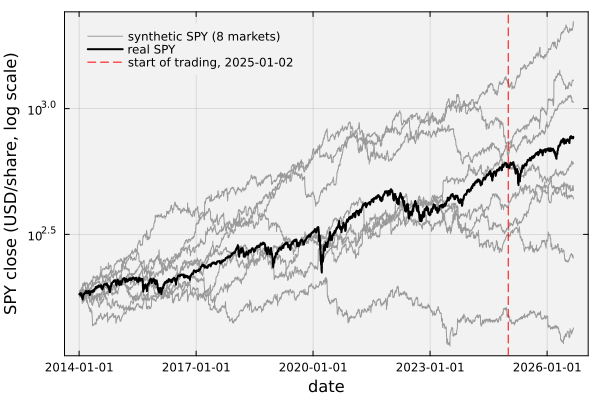

In [6]:
let

    # initialize: the real SPY close and the first eight synthetic ones -
    markets = [MPC.synthetic_market_data(generator, md, p) for p in 1:8]; # eight synthetic markets

    # plot: synthetic SPY in gray, the real one in black, and the start of trading -
    plot(md.dates, markets[1].spy_close, lw = 1, c = :gray60, label = "synthetic SPY (8 markets)", yscale = :log10,
        bg = "gray95", background_color_outside = "white", framestyle = :box, fg_legend = :transparent, legend = :topleft);
    for m in markets[2:end]
        plot!(md.dates, m.spy_close, lw = 1, c = :gray60, label = "");
    end
    plot!(md.dates, md.spy_close, lw = 2, c = :black, label = "real SPY");
    vline!([Date(2025, 1, 2)], c = :red, ls = :dash, lw = 1, label = "start of trading, 2025-01-02");
    xlabel!("date"); ylabel!("SPY close (USD/share, log scale)")
end

___

## Task 2: Choose Typical and Sell-off Markets
In this task, we choose the markets to test on. [The `MPC.market_path_stats(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-synthetic/) draws only the `SPY` path of each candidate, which is fast, and measures over the trading window (January 2, 2025 to September 4, 2026) its largest drawdown, its growth rate, and whether a burst of large moves (a jump episode) fell in the window. [The `MPC.path_sets(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-synthetic/) then picks three sets, as the study does:
* __Typical:__ a random sample of the candidates.
* __Burst sell-offs:__ the deepest drawdowns among the candidates with a burst in the window.
* __Bear sell-offs:__ the deepest drawdowns among the candidates without a burst, so their declines are slower and more sustained.

We store the sets in the `sets::DataFrame` variable:

In [7]:
sets = let

    # SPY statistics of every candidate, then the three sets -
    stats = MPC.market_path_stats(generator, md, candidates);
    s = MPC.path_sets(stats; n_burst = n_burst, n_bear = n_bear, n_typical = n_typical, seed = random_seed);
    println("$(length(candidates)) candidates, $(count(stats.has_burst)) with a burst in the trading window");

    # checks -
    @assert count(s.typical) == n_typical && count(s.burst_stress) == n_burst && count(s.bear_stress) == n_bear "set sizes"

    # return -
    s
end;

2000 candidates, 112 with a burst in the trading window


Let's compare the three sets. The table shows the number of markets in each, and the median over its markets of the `SPY` growth rate and the largest `SPY` drawdown in the trading window, next to the real values:

In [8]:
let

    # initialize: the real SPY over the trading window -
    i0, i1 = MPC.index_of(md, Date(2025, 1, 2)), MPC.index_of(md, Date(2026, 9, 4)); # trading window rows
    real = md.spy_close[i0:i1]; # real SPY close (USD/share)
    real_g = log(real[end] / real[1]) / ((i1 - i0) / 252); # real growth rate (1/yr)
    real_dd = maximum(1 .- real ./ accumulate(max, real)); # real largest drawdown

    # one row per set, then the real market -
    rows = [(set = name, markets = count(mask), g = median(sets.window_growth[mask]), drawdown = median(sets.window_max_drawdown[mask]))
        for (name, mask) in (("typical", sets.typical), ("burst sell-off", sets.burst_stress), ("bear sell-off", sets.bear_stress))];
    push!(rows, (set = "real SPY", markets = 1, g = real_g, drawdown = real_dd));

    # show the table -
    pretty_table(DataFrame(rows); column_labels = ["set", "markets", "median SPY growth rate (1/yr)", "median largest SPY drawdown"],
        alignment = [:l, :r, :r, :r], formatters = [fmt__printf("%.3f", [3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ---------------- --------- ------------------------------- -----------------------------
  set              markets   median SPY growth rate (1/yr)   median largest SPY drawdown 
 ---------------- --------- ------------------------------- -----------------------------
  typical               16                           0.084                         0.193
  burst sell-off         6                          -0.154                         0.522
  bear sell-off          6                          -0.243                         0.460
  real SPY               1                           0.166                         0.190
 ---------------- --------- ------------------------------- -----------------------------


> __What do we see?__ The typical markets resemble the real one in their drawdown: a median of 0.193 against the real 0.190, though their median growth rate, 0.084 (1/yr), is below the real 0.166. Both sell-off sets lost far more, with median drawdowns near one half, deeper than anything in the real window. Only 112 of the 2,000 candidates had a burst in the window.
___

## Task 3: Run the Method on Every Market
In this task, we run the method on each chosen market. [The `MPC.run_synthetic_path(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-synthetic/) calibrates the method on the market's own 2014 to 2024, as it was calibrated on the real data, and runs each book on the market's 2025 and 2026. We run four books on every market:
* __Cobb–Douglas, γ picker:__ the book of the real-data example.
* __Cobb–Douglas, random picker:__ the same rule with random names, three per sector.
* __CES, γ picker:__ another weighting rule on the γ basket.
* __Cobb–Douglas, γ picker, hedge on:__ the β-cap hedge.

The generator always draws all 373 names, so every name keeps its sector draws; the books then trade the `n_tickers` names that [the `MPC.select_universe(...)` function](https://varnerlab.org/CHEME-5660-CourseRepository-Fall-2026/dev/mpc-data/) picks from the real data, the same names as in the real-data example. Next to the books, we record two references on the same market: `SPY` and an equal-weight portfolio of those names, bought at the first close of the window and held. A market whose growth rates do not give finite prices is skipped and counted. This cell takes a few minutes; it prints its progress. We store one row per market and book in the `results::DataFrame` variable:

In [9]:
results = let

    # initialize: the four books, the markets in run order, and the trading window rows -
    runs = [build(MPC.MyStudyRun, (settings = settings, allocator = "CD", screen = :gamma, seed = random_seed, label = "CD, γ")),
        build(MPC.MyStudyRun, (settings = settings, allocator = "CD", screen = :random, seed = random_seed, label = "CD, random")),
        build(MPC.MyStudyRun, (settings = settings, allocator = "CES", screen = :gamma, seed = random_seed, label = "CES, γ")),
        build(MPC.MyStudyRun, (settings = settings_hedged, allocator = "CD", screen = :gamma, seed = random_seed, label = "CD, γ, hedge"))];
    chosen = sort(sets[.!ismissing.(sets.run_order), :], :run_order); # the markets of the three sets
    i0, i1 = MPC.index_of(md, settings.start), MPC.index_of(md, settings.stop); # trading window rows
    names = MPC.select_universe(md, n_tickers); # the names the books trade (all of them at 373)
    rows = DataFrame();
    skipped = 0;

    # main loop: one market at a time -
    for (k, r) in enumerate(eachrow(chosen))
        market = try
            MPC.subset_universe(MPC.synthetic_market_data(generator, md, r.path_id), names)
        catch err
            err isa MPC.NonFiniteCloseError || rethrow(); # only a non-finite close is skipped
            skipped += 1;
            continue
        end
        out = MPC.run_synthetic_path(market, runs); # calibrate on 2014–2024, then run the four books
        out[!, :path_id] .= r.path_id;
        out[!, :typical] .= r.typical;
        out[!, :burst] .= r.burst_stress;
        out[!, :bear] .= r.bear_stress;
        out[!, :ew_ratio] .= mean(market.close[i1, :] ./ market.close[i0, :]); # equal-weight portfolio of the names
        append!(rows, out);
        k % 5 == 0 && println("market $(k) of $(nrow(chosen)) done");
    end
    println("$(length(names)) names; $(nrow(chosen) - skipped) markets run, $(skipped) skipped; $(count(rows.status .== "ok")) of $(nrow(rows)) books finished");

    # checks -
    @assert nrow(rows) == 4 * (nrow(chosen) - skipped) "four books per market"
    @assert all(rows.status .== "ok") "every book should finish"

    # return -
    rows
end;

market 5 of 28 done


market 10 of 28 done


market 15 of 28 done


market 20 of 28 done


market 25 of 28 done


373 names; 28 markets run, 0 skipped; 112 of 112 books finished


___

## Task 4: Read the Results as Distributions
In this task, we summarize each set. For every book and both references, the table shows the median, over the set's markets, of the ending wealth over the starting wealth, and the share of markets where the book ended above `SPY`:

In [10]:
let

    # initialize: the books and the sets -
    books = ["CD, γ", "CD, random", "CES, γ", "CD, γ, hedge"];
    groups = (("typical", :typical), ("burst sell-off", :burst), ("bear sell-off", :bear));
    rows = [];

    # one row per set and book, then the two references -
    for (name, col) in groups
        part = results[results[!, col], :]; # this set's rows
        for b in books
            d = part[part.label .== b, :];
            push!(rows, (set = name, series = b, median_ratio = median(d.wealth_ratio), above_spy = mean(d.wealth_ratio .> d.spy_ratio)));
        end
        one = part[part.label .== books[1], :]; # one row per market, for the references
        push!(rows, (set = name, series = "SPY", median_ratio = median(one.spy_ratio), above_spy = missing));
        push!(rows, (set = name, series = "equal weight, universe", median_ratio = median(one.ew_ratio), above_spy = mean(one.ew_ratio .> one.spy_ratio)));
    end

    # show the table -
    pretty_table(DataFrame(rows); column_labels = ["set", "book or reference", "median ending ÷ starting wealth", "share above SPY"],
        alignment = [:l, :l, :r, :r], formatters = [fmt__printf("%.3f", [3, 4])],
        table_format = TextTableFormat(borders = text_table_borders__compact), fit_table_in_display_horizontally = false);
end

 ---------------- ------------------------ --------------------------------- -----------------
  set              book or reference        median ending ÷ starting wealth   share above SPY 
 ---------------- ------------------------ --------------------------------- -----------------
  typical          CD, γ                                              1.207             0.750
  typical          CD, random                                         1.052             0.375
  typical          CES, γ                                             1.219             0.688
  typical          CD, γ, hedge                                       1.158             0.688
  typical          SPY                                                1.151           missing
  typical          equal weight, universe                             1.175             0.812
  burst sell-off   CD, γ                                              0.906             1.000
  burst sell-off   CD, random                            

> __What do we see?__ In both sell-off sets, every book's median ended above the median `SPY` and above the equal-weight portfolio: in the burst set the books ended between 0.906 and 1.025 times their starting wealth, while `SPY` lost about a fifth. In the typical set the medians ranged from 1.052 to 1.219, around `SPY`'s 1.151. The equal-weight portfolio itself ended above `SPY` in most markets.

Next, the picker. On each market, we compare the Cobb–Douglas books with the γ picker and with the random picker, which differ only in the names they hold:

In [11]:
let

    # on each market, did the γ book end above the random book? -
    for (name, col) in (("typical", :typical), ("burst sell-off", :burst), ("bear sell-off", :bear))
        part = results[results[!, col], :]; # this set's rows
        γ = part[part.label .== "CD, γ", :]; # one row per market, in market order
        rnd = part[part.label .== "CD, random", :];
        @assert γ.path_id == rnd.path_id "the same markets in the same order"
        println(rpad(name, 16), ": γ above random on $(count(γ.wealth_ratio .> rnd.wealth_ratio)) of $(nrow(γ)) markets");
    end
end

typical         : γ above random on 13 of 16 markets
burst sell-off  : γ above random on 2 of 6 markets
bear sell-off   : γ above random on 3 of 6 markets


> __What do we see?__ The γ picker ended above the random picker on 13 of the 16 typical markets, but on only 2 of the 6 burst markets and 3 of the 6 bear markets. With six markets per sell-off set these counts are rough; the study used 200 per set.

`Unhide` the code block below to see how we plotted the ending wealth over the starting wealth of each book and reference on every market, set by set.

> __What do we see?__ In the typical markets, every book and both references spread widely, from about 0.8 to 2.0 times the starting wealth, and the spreads overlap. In the burst sell-offs, every book sits above `SPY` on every market; in the bear set, the books sit above `SPY` on most markets. In the bear set, no book got back to its starting wealth.

How do the books compare with the references, set by set?

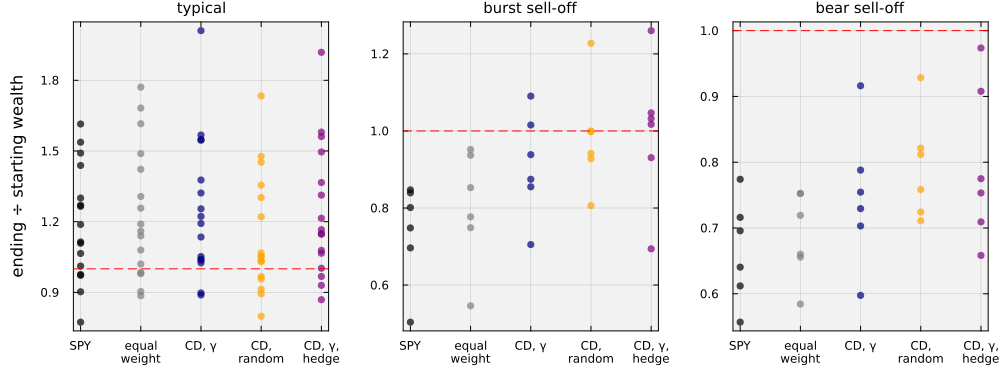

In [12]:
let

    # initialize: the series to plot, their colors, and the sets -
    series = ["CD, γ", "CD, random", "CD, γ, hedge"]; # three of the books
    colors = [:navy, :orange, :purple];
    groups = (("typical", :typical), ("burst sell-off", :burst), ("bear sell-off", :bear));
    panels = [];

    # one panel per set: a dot per market for each book, SPY, and the equal-weight portfolio -
    for (name, col) in groups
        part = results[results[!, col], :];
        one = part[part.label .== series[1], :];
        p = scatter(fill(1, nrow(one)), one.spy_ratio, c = :black, ms = 4, msw = 0, alpha = 0.7, label = "",
            bg = "gray95", background_color_outside = "white", framestyle = :box, title = name, titlefontsize = 10,
            ylabel = name == "typical" ? "ending ÷ starting wealth" : "");
        scatter!(p, fill(2, nrow(one)), one.ew_ratio, c = :gray50, ms = 4, msw = 0, alpha = 0.7, label = "");
        for (j, b) in enumerate(series)
            d = part[part.label .== b, :];
            scatter!(p, fill(2 + j, nrow(d)), d.wealth_ratio, c = colors[j], ms = 4, msw = 0, alpha = 0.7, label = "");
        end
        hline!(p, [1.0], c = :red, ls = :dash, lw = 1, label = "");
        xticks!(p, 1:5, ["SPY", "equal\nweight", "CD, γ", "CD,\nrandom", "CD, γ,\nhedge"]);
        push!(panels, p);
    end
    plot(panels..., layout = (1, 3), size = (1000, 380), bottom_margin = 6Plots.mm, left_margin = 6Plots.mm)
end

> __What the study found:__ On 600 typical markets and 200 markets in each sell-off set, the study reports that in the deepest simulated declines every combination, random picks included, ended above simulated `SPY` and the equal-weight universe in the median. The equal-weight universe also ended above simulated `SPY`, so part of the margin came from the simulated market and the rest from parts of the system all books share, not from stock selection. It also reports that the generator's persistent trends favored the γ picker more than the real market did. Our classroom run is much smaller, and its sell-off sets show the same ordering of the books and references.

Your numbers will differ if you change the constants: try more markets per set, other `candidates`, or another `random_seed`.
___

## Summary
In this example, we tested the portfolio method of the INFORMS 2026 study on synthetic markets drawn from a generator fitted to the same 373 names.

> __Key Takeaways:__
>
> * __A fitted generator gives many markets that could have happened:__ We loaded the generator fitted to the 373 names, whose β drift and intercepts were calibrated to the method's own estimates, and drew whole markets on the real calendar. Their `SPY` paths spread widely around the real one.
> * __Sell-off sets probe declines the real window never held:__ We measured the drawdown and the bursts of each candidate's `SPY` and chose typical markets and two sets of deep sell-offs. The sell-off markets lost about half their peak, while the real `SPY` lost less than a fifth.
> * __Results are distributions, read set by set:__ We ran four books on every market. In the sell-offs the median books ended above `SPY` and the equal-weight portfolio, while in typical markets they spread around `SPY`. The γ picker beat random picks on most typical markets but on only two of the six markets in each sell-off set.

The study found that its generator's persistent trends favored the γ picker more than the real market did, so part of what a synthetic test shows can come from the generator itself.
___

## Disclaimer and Risks
__This content is offered solely for training and informational purposes__. No offer or solicitation to buy or sell securities or derivative products or any investment or trading advice or strategy is made, given, or endorsed by the teaching team.

__Trading involves risk__. Carefully review your financial situation before investing in securities, futures contracts, options, or commodity interests. Past performance, whether actual or indicated by historical tests of strategies, is no guarantee of future performance or success. Trading is generally inappropriate for someone with limited resources, investment or trading experience, or a low-risk tolerance. Only risk capital that is not required for living expenses should be used.

__You are fully responsible for any investment or trading decisions you make__. Such decisions should be based solely on evaluating your financial circumstances, investment or trading objectives, risk tolerance, and liquidity needs.

___